# Machine Learning — Practical Session 1
## Exercise 1: Exploring a Tabular Dataset

**Objective:** Load and explore the Iris dataset using pandas.

In [1]:
# ============================================================
# EXERCISE 1 — Exploring a Tabular Dataset
# STEP 1 — Load the Iris dataset
# ============================================================

# Import pandas to work with tabular data
import pandas as pd

# Import Path to locate the dataset file
from pathlib import Path

# Find the dataset whether the notebook runs from
# the project root or from the submissions/TP1 folder
if Path("../../machine-learning-tp1-starter/data/Iris_Dataset.csv").exists():
    iris_path = Path("../../machine-learning-tp1-starter/data/Iris_Dataset.csv")
elif Path("machine-learning-tp1-starter/data/Iris_Dataset.csv").exists():
    iris_path = Path("machine-learning-tp1-starter/data/Iris_Dataset.csv")
else:
    raise FileNotFoundError(
        "Iris_Dataset.csv was not found. "
        "Make sure you opened the machine-learning-tp1 project."
    )

# Load the CSV file into a DataFrame named D
D = pd.read_csv(iris_path)

print("Iris dataset loaded successfully!")

Iris dataset loaded successfully!


### Step 2: Inspecting the Dataset

Inspect the dataset structure, statistical summaries, dimensions,
column names, and first observations.

In [2]:

# ============================================================
# EXERCISE 1 — STEP 2: Inspect the Iris dataset
# ============================================================

# 1. Display column information and data types
print("1. Dataset information:")
D.info()

# 2. Display descriptive statistics for numerical columns
print("\n2. Descriptive statistics:")
display(D.describe())

# 3. Display the number of rows and columns
print("\n3. Dataset dimensions:")
print(D.shape)

# 4. Display all column names
print("\n4. Column names:")
print(D.columns)

# 5. Display the first five observations
print("\n5. First five observations:")
display(D.head())


1. Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

2. Descriptive statistics:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



3. Dataset dimensions:
(150, 5)

4. Column names:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

5. First five observations:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### Step 3: Selecting Features

Select `sepal_length` and `petal_width` from the original dataset
and display the first 20 observations.

In [3]:

# ============================================================
# EXERCISE 1 — STEP 3: Feature Selection
# ============================================================

# Select two columns and store them in a new DataFrame
selected_features = D[["sepal_length", "petal_width"]]

# Display the first 20 observations
print("First 20 observations of the selected features:")
display(selected_features.head(20))


First 20 observations of the selected features:


,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


### Step 4: Creating a Copy of the Original Dataset

Create a copy of the original DataFrame to preserve the original
data while experimenting with preprocessing.

In [4]:

# ============================================================
# EXERCISE 1 — STEP 4: Copy the original DataFrame
# ============================================================

# Create a separate copy of the complete original dataset
D_copy = D.copy()

# Compare the dimensions of the original and copied datasets
print("Original dataset shape:", D.shape)
print("Copied dataset shape:", D_copy.shape)

# Check that D_copy is a separate DataFrame object
print("Is D_copy a separate object?", D_copy is not D)

# Display the first five rows of the copy
display(D_copy.head())


Original dataset shape: (150, 5)
Copied dataset shape: (150, 5)
Is D_copy a separate object? True


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### Step 5: Splitting Data into Training and Test Sets

Use the selected input features and the species target to create
an 80% training set and a 20% test set. Use a fixed random state
and stratify by the target class.

In [5]:

# ============================================================
# EXERCISE 1 — STEP 5: Training/Test Split
# ============================================================

from sklearn.model_selection import train_test_split

# Define the input features (X)
X = D_copy[["sepal_length", "petal_width"]]

# Define the target variable (y)
y = D_copy["species"]

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data splitting completed successfully!")


Data splitting completed successfully!


### Step 6: Verifying the Training and Test Sets

Check the number of observations and proportions in each set.
Also compare the class proportions to verify stratification.

In [6]:

# ============================================================
# EXERCISE 1 — STEP 6: Verify the data split
# ============================================================

# Count observations in each set
print("Original dataset:", len(D_copy))
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

# Display the dimensions: (rows, columns)
print("\nTraining features shape:", X_train.shape)
print("Test features shape:", X_test.shape)

# Calculate the proportions of the two sets
training_ratio = len(X_train) / len(D_copy)
test_ratio = len(X_test) / len(D_copy)

print(f"\nTraining proportion: {training_ratio:.0%}")
print(f"Test proportion: {test_ratio:.0%}")

# Compare class proportions in the training and test sets
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index())

print("Test class proportions:")
display(y_test.value_counts(normalize=True).sort_index())


Original dataset: 150
Training observations: 120
Test observations: 30

Training features shape: (120, 2)
Test features shape: (30, 2)

Training proportion: 80%
Test proportion: 20%

Training class proportions:


species
Iris-setosa        0.333333
Iris-versicolor    0.333333
Iris-virginica     0.333333
Name: proportion, dtype: float64

Test class proportions:


species
Iris-setosa        0.333333
Iris-versicolor    0.333333
Iris-virginica     0.333333
Name: proportion, dtype: float64

# Exercise 2: Exploring Text Data

## Step 1: Open and Read the Text File

Read `txt_file.txt` using UTF-8 encoding.

In [7]:
# ============================================================
# EXERCISE 2 — STEP 1: Open and read the text file
# ============================================================

from pathlib import Path

# Find the text file
if Path("../../machine-learning-tp1-starter/data/txt_file.txt").exists():
    txt_path = Path("../../machine-learning-tp1-starter/data/txt_file.txt")
elif Path("machine-learning-tp1-starter/data/txt_file.txt").exists():
    txt_path = Path("machine-learning-tp1-starter/data/txt_file.txt")
else:
    raise FileNotFoundError("txt_file.txt was not found.")

# Open the file and read its contents
with open(txt_path, "r", encoding="utf-8") as file:
    content = file.read()

# Display the file contents
print(content)

0.50,0.20,0.84,0.01,c1
0.10,0.10,0.40,0.02,c2
0.15,0.10,0.45,0.03,c2
0.22,0.20,0.90,0.01,c1
0.25,0.20,0.87,0.01,c1
0.10,0.10,0.38,0.02,c2



### Step 2: Read the File Line by Line

Loop through the file and print each line without its trailing newline character.

In [8]:
# ============================================================
# EXERCISE 2 — STEP 2: Read line by line
# ============================================================

# Open the file and process each line separately
with open(txt_path, "r", encoding="utf-8") as file:
    for line in file:
        # Remove only the trailing newline character
        print(line.rstrip("\n"))

0.50,0.20,0.84,0.01,c1
0.10,0.10,0.40,0.02,c2
0.15,0.10,0.45,0.03,c2
0.22,0.20,0.90,0.01,c1
0.25,0.20,0.87,0.01,c1
0.10,0.10,0.38,0.02,c2


### Step 3: Load the 20 Newsgroups Dataset

Load the training subset using scikit-learn's `fetch_20newsgroups()`.

In [9]:

# ============================================================
# EXERCISE 2 — STEP 3: Load 20 Newsgroups
# ============================================================

# Import the dataset loader
from sklearn.datasets import fetch_20newsgroups

# Load the training subset using the default categories
newsgroups = fetch_20newsgroups(subset="train")

print("20 Newsgroups dataset loaded successfully!")


20 Newsgroups dataset loaded successfully!


### Step 4: Count Documents and Labels

Display the number of documents, target labels, and available classes.

In [10]:

# ============================================================
# EXERCISE 2 — STEP 4: Count documents and labels
# ============================================================

# Count the text documents
print("Number of documents:", len(newsgroups.data))

# Count the target label assigned to each document
print("Number of target labels:", len(newsgroups.target))

# Count the available classes
print("Number of classes:", len(newsgroups.target_names))


Number of documents: 11314
Number of target labels: 11314
Number of classes: 20


### Step 5: Display the First Document

Display the text of the first document and check its target label.

In [11]:

# ============================================================
# EXERCISE 2 — STEP 5: Display the first document
# ============================================================

# Display the first text document
print("First document:")
print(newsgroups.data[0])

# Display the numeric target label of the first document
print("\nTarget label:")
print(newsgroups.target[0])


First document:
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.

Thanks,
- IL
   ---- brought to you by your neighborhood Lerxst ----






Target label:
7


### Step 6: Display Class Names

Display the available class names and find the class name
associated with the first document.

In [12]:

# ============================================================
# EXERCISE 2 — STEP 6: Display class names
# ============================================================

# Display all available class names
print("Available class names:")
print(newsgroups.target_names)

# Get the numeric label of the first document
first_label = newsgroups.target[0]

# Use the label to find the corresponding class name
first_class_name = newsgroups.target_names[first_label]

print("\nFirst document label:", first_label)
print("First document class:", first_class_name)


Available class names:
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

First document label: 7
First document class: rec.autos


# Exercise 3: Missing Values

## Step 1 - Load and inspect employees.csv

Load the employee dataset and check its columns, data types,
and first few rows.

In [13]:

# ============================================================
# EXERCISE 3 — STEP 1: Load and inspect employee data
# ============================================================

from pathlib import Path
import pandas as pd

# Find the employee dataset
if Path("../../machine-learning-tp1-starter/data/employees.csv").exists():
    employees_path = Path("../../machine-learning-tp1-starter/data/employees.csv")
elif Path("machine-learning-tp1-starter/data/employees.csv").exists():
    employees_path = Path("machine-learning-tp1-starter/data/employees.csv")
else:
    raise FileNotFoundError("employees.csv was not found.")

# Load the dataset
employees = pd.read_csv(employees_path)

# Display the column names
print("Column names:")
print(employees.columns.tolist())

# Check the data types and non-null counts
print("\nDataset information:")
employees.info()

# Display the first five rows
print("\nFirst five rows:")
display(employees.head())


Column names:
['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Salary', 'Bonus %', 'Senior Management', 'Team']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    object 
 1   Gender             855 non-null    object 
 2   Start Date         1000 non-null   object 
 3   Last Login Time    1000 non-null   object 
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    object 
dtypes: float64(1), int64(1), object(6)
memory usage: 62.6+ KB

First five rows:


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


### Step 2 - Count Missing Values

Count the missing values in each column using `isna().sum()`.

In [14]:
# ============================================================
# EXERCISE 3 — STEP 2: Count missing values
# ============================================================

# Count the missing values in each column
missing_counts = employees.isna().sum()

# Display the result
print("Missing values in each column:")
print(missing_counts)

Missing values in each column:
First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64


### Step 3 - Visualize Missing Values

Use a Seaborn heatmap to visualize missing values in the employee dataset.

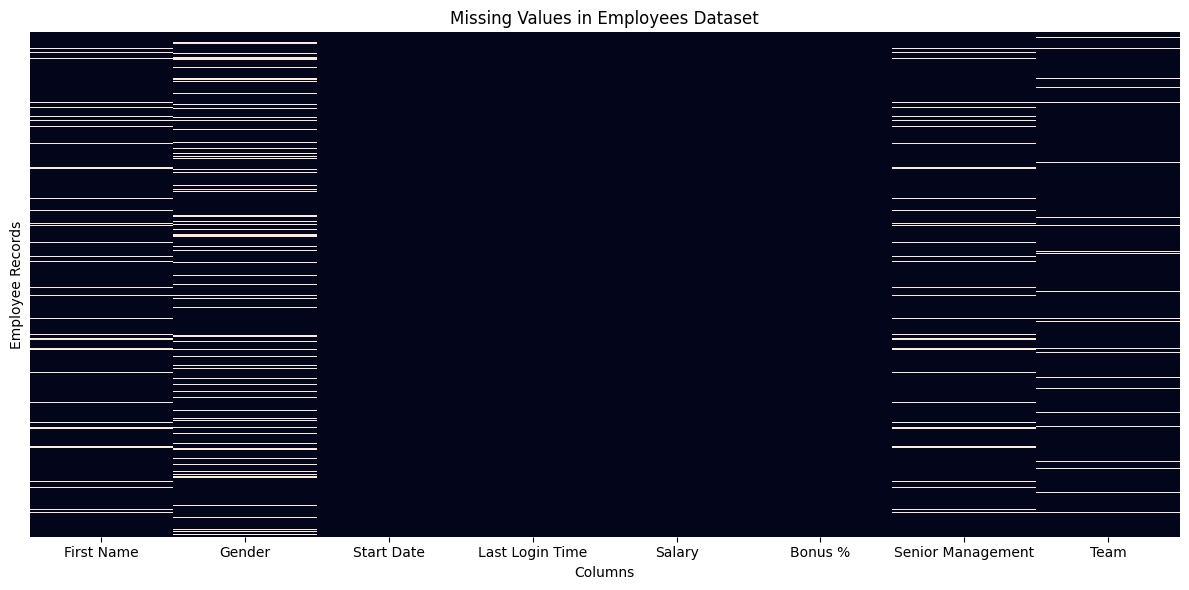

In [15]:

# ============================================================
# EXERCISE 3 — STEP 3: Visualize missing values
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt

# Mark missing cells as True and existing cells as False
missing_map = employees.isna()

# Create the heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(
    missing_map,
    cbar=False,
    yticklabels=False
)

# Add a title and clear axis labels
plt.title("Missing Values in Employees Dataset")
plt.xlabel("Columns")
plt.ylabel("Employee Records")

# Adjust the layout and display the plot
plt.tight_layout()
plt.show()


### Step 4 - Add a Row with Missing Values

Create a copy of the employee dataset and add one synthetic row
with eight fields.

In [16]:
# ============================================================
# EXERCISE 3 — STEP 4: Add a synthetic row
# ============================================================

import numpy as np

# Keep the original dataset unchanged
employees_copy = employees.copy()

# Create one new row with eight fields
new_row = {
    "First Name": "-",
    "Gender": "na",
    "Start Date": np.nan,
    "Last Login Time": np.nan,
    "Salary": np.nan,
    "Bonus %": np.nan,
    "Senior Management": np.nan,
    "Team": np.nan
}

# Add the new row to the copy
employees_copy = pd.concat(
    [employees_copy, pd.DataFrame([new_row])],
    ignore_index=True
)

# Check the result
print("Original dataset shape:", employees.shape)
print("Dataset shape after adding the row:", employees_copy.shape)

print("\nNew row:")
display(employees_copy.tail(1))

Original dataset shape: (1000, 8)
Dataset shape after adding the row: (1001, 8)

New row:


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
1000,-,na,NaN,NaN,NaN,NaN,NaN,NaN


### Step 5 - Recount Missing Values

Count the missing values after adding the new row and compare
them with the original dataset.

In [17]:

# ============================================================
# EXERCISE 3 — STEP 5: Recount missing values
# ============================================================

# Count missing values in the original dataset
original_missing = employees.isna().sum()

# Count missing values after adding the new row
updated_missing = employees_copy.isna().sum()

# Compare the counts before and after adding the row
missing_comparison = pd.DataFrame({
    "Original": original_missing,
    "After adding row": updated_missing
})

print("Missing values before and after adding the row:")
display(missing_comparison)

# Check whether '-' and 'na' are detected as missing
print("\nAre '-' and 'na' detected as missing?")
display(employees_copy.tail(1).isna())


Missing values before and after adding the row:


,Original,After adding row
First Name,67,67
Gender,145,145
Start Date,0,1
Last Login Time,0,1
Salary,0,1
Bonus %,0,1
Senior Management,67,68
Team,43,44



Are '-' and 'na' detected as missing?


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
1000,False,False,True,True,True,True,True,True


### Step 6 - Replace missing-value markers

Replace the exact strings `-` and `na` with `np.nan`.

In [18]:

# ============================================================
# EXERCISE 3 — STEP 6: Replace missing-value markers
# ============================================================

# Count missing values before replacing the markers
missing_before = employees_copy.isna().sum()

# Replace the agreed markers with actual missing values
# Rule: replace "-" and lowercase "na" exactly as written
employees_copy = employees_copy.replace({
    "-": np.nan,
    "na": np.nan
})

# Count missing values after replacement
missing_after = employees_copy.isna().sum()

# Compare the results
marker_comparison = pd.DataFrame({
    "Before replacement": missing_before,
    "After replacement": missing_after
})

print("Missing values before and after replacement:")
display(marker_comparison)

# Check the last row
print("Last row after replacement:")
display(employees_copy.tail(1))

# Confirm that the original dataset was not changed
print("Original dataset shape:", employees.shape)


Missing values before and after replacement:


,Before replacement,After replacement
First Name,67,68
Gender,145,146
Start Date,1,1
Last Login Time,1,1
Salary,1,1
Bonus %,1,1
Senior Management,68,68
Team,44,44


Last row after replacement:


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Original dataset shape: (1000, 8)


### Step 7 - Handle Missing Values

Use SimpleImputer with the median for numerical columns
and the most frequent value for selected categorical columns.

In [19]:

# ============================================================
# EXERCISE 3 — STEP 7: Handle missing values
# ============================================================

from sklearn.impute import SimpleImputer

# Keep a copy for the imputation experiment
imputed_employees = employees_copy.copy()

# Choose numerical and categorical columns
numeric_cols = ["Salary", "Bonus %"]
categorical_cols = ["Gender", "Senior Management", "Team"]

# Fill numerical missing values using the median
numeric_imputer = SimpleImputer(strategy="median")
imputed_employees[numeric_cols] = numeric_imputer.fit_transform(
    imputed_employees[numeric_cols]
)

# Fill categorical missing values using the most frequent value
categorical_imputer = SimpleImputer(strategy="most_frequent")
imputed_employees[categorical_cols] = categorical_imputer.fit_transform(
    imputed_employees[categorical_cols]
)

# Display the filled columns
print("Imputation completed.")
print("\nMissing values in the selected columns:")
print(imputed_employees[numeric_cols + categorical_cols].isna().sum())

# Show the synthetic row after imputation
print("\nLast row after imputation:")
display(imputed_employees.tail(1))


Imputation completed.

Missing values in the selected columns:
Salary               0
Bonus %              0
Gender               0
Senior Management    0
Team                 0
dtype: int64

Last row after imputation:


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
1000,NaN,Female,NaN,NaN,90428.0,9.8385,True,Client Services


### Step 8 - Compare Before and After Imputation

Compare the missing-value counts before and after imputation
and explain the limitations of the method.

In [20]:

# ============================================================
# EXERCISE 3 — STEP 8: Compare imputation results
# ============================================================

# Count missing values before and after imputation
missing_before = employees_copy.isna().sum()
missing_after = imputed_employees.isna().sum()

# Compare the counts in each column
comparison = pd.DataFrame({
    "Before imputation": missing_before,
    "After imputation": missing_after
})

print("Missing values before and after imputation:")
display(comparison)

# Display columns that still contain missing values
print("\nColumns that still have missing values:")
print(missing_after[missing_after > 0])

# Count missing values in the whole dataset
print("\nTotal missing values before:", missing_before.sum())
print("Total missing values after:", missing_after.sum())


Missing values before and after imputation:


,Before imputation,After imputation
First Name,68,68
Gender,146,0
Start Date,1,1
Last Login Time,1,1
Salary,1,0
Bonus %,1,0
Senior Management,68,0
Team,44,0



Columns that still have missing values:
First Name         68
Start Date          1
Last Login Time     1
dtype: int64

Total missing values before: 330
Total missing values after: 70


# Exercise 4: Feature Scaling and Encoding

## Part A - Step 1: Scaling Numerical Data

Apply five scaling and normalization methods to the given matrix.

In [21]:

# ============================================================
# EXERCISE 4 — PART A — STEP 1: Feature Scaling
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    MaxAbsScaler,
    RobustScaler,
    normalize
)

# Create the original numerical matrix
scaling_matrix = np.array([
    [1, -1,  2],
    [2,  0,  0],
    [0,  1, -1]
], dtype=float)

# Give the columns readable names
feature_names = ["Feature 1", "Feature 2", "Feature 3"]

# Display the original matrix
print("Original matrix:")
display(pd.DataFrame(scaling_matrix, columns=feature_names))

# 1. StandardScaler: scale each feature using its mean and standard deviation
standard_scaled = StandardScaler().fit_transform(scaling_matrix)

print("\nStandardScaler:")
display(pd.DataFrame(standard_scaled, columns=feature_names))

# 2. MinMaxScaler: scale each feature to the range [0, 1]
minmax_scaled = MinMaxScaler().fit_transform(scaling_matrix)

print("\nMinMaxScaler:")
display(pd.DataFrame(minmax_scaled, columns=feature_names))

# 3. MaxAbsScaler: divide each feature by its maximum absolute value
maxabs_scaled = MaxAbsScaler().fit_transform(scaling_matrix)

print("\nMaxAbsScaler:")
display(pd.DataFrame(maxabs_scaled, columns=feature_names))

# 4. RobustScaler: use the median and interquartile range
robust_scaled = RobustScaler().fit_transform(scaling_matrix)

print("\nRobustScaler:")
display(pd.DataFrame(robust_scaled, columns=feature_names))

# 5. normalize: normalize each sample (row) using the L2 norm
normalized_matrix = normalize(scaling_matrix)

print("\nnormalize:")
display(pd.DataFrame(normalized_matrix, columns=feature_names))


Original matrix:


,Feature 1,Feature 2,Feature 3
0,1.0,-1.0,2.0
1,2.0,0.0,0.0
2,0.0,1.0,-1.0



StandardScaler:


,Feature 1,Feature 2,Feature 3
0,0.000000,-1.224745,1.336306
1,1.224745,0.000000,-0.267261
2,-1.224745,1.224745,-1.069045



MinMaxScaler:


...

,Feature 1,Feature 2,Feature 3
0,0.5,-1.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,-0.5



RobustScaler:


,Feature 1,Feature 2,Feature 3
0,0.0,-1.0,1.333333
1,1.0,0.0,0.000000
2,-1.0,1.0,-0.666667



normalize:


,Feature 1,Feature 2,Feature 3
0,0.408248,-0.408248,0.816497
1,1.000000,0.000000,0.000000
2,0.000000,0.707107,-0.707107


### Part A - Step 2: Binarization

Convert the original numerical matrix into binary values
using a threshold of 0.5.

In [22]:

# ============================================================
# EXERCISE 4 — PART A — STEP 2: Binarization
# ============================================================

from sklearn.preprocessing import Binarizer

# Choose the threshold
threshold = 0.5

# Create the binarizer and transform the original matrix
binarizer = Binarizer(threshold=threshold)
binary_matrix = binarizer.fit_transform(scaling_matrix)

# Display the original matrix and the binary result
print("Original matrix:")
display(pd.DataFrame(scaling_matrix, columns=feature_names))

print(f"\nBinarized matrix (threshold = {threshold}):")
display(pd.DataFrame(binary_matrix, columns=feature_names))


Original matrix:


,Feature 1,Feature 2,Feature 3
0,1.0,-1.0,2.0
1,2.0,0.0,0.0
2,0.0,1.0,-1.0



Binarized matrix (threshold = 0.5):


,Feature 1,Feature 2,Feature 3
0,1.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,0.0



### Part A - Step 3: Comparison and Discussion

**Comparison of scaling methods**

- `StandardScaler` uses the mean and standard deviation.
- `MinMaxScaler` scales each feature to the range 0 to 1.
- `MaxAbsScaler` divides each feature by its maximum absolute value.
- `RobustScaler` uses the median and interquartile range.
- `normalize` scales each sample (row) to unit norm by default.

**Why is scaling useful?**

Scaling can matter for KNN because it uses distances between samples. It is also important for many SVM models and can help gradient-based algorithms converge more efficiently.

Decision trees usually do not need scaling because their splits depend mainly on feature values and thresholds, not on distances between features.

## Part B: Categorical Encoding

### Step 1 - Encode the input features

Use OrdinalEncoder to convert the three categorical input
features into numerical codes.

In [23]:

# ============================================================
# EXERCISE 4 — PART B — STEP 1: Ordinal Encoding
# ============================================================

import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

# Create the dataset from the exercise
categorical_data = pd.DataFrame({
    "Feature 1": ["male", "female", "female", "male"],
    "Feature 2": ["from US", "from Europe", "from Asia", "from Africa"],
    "Feature 3": ["uses Safari", "uses Safari", "uses Firefox", "uses Chrome"],
    "Target": ["US", "France", "Japan", "Algeria"]
})

# Select only the input features
X_categorical = categorical_data[
    ["Feature 1", "Feature 2", "Feature 3"]
]

# Create the encoder
ordinal_encoder = OrdinalEncoder()

# Encode the input features
X_encoded = ordinal_encoder.fit_transform(X_categorical)

# Display the encoded values
encoded_features = pd.DataFrame(
    X_encoded,
    columns=X_categorical.columns
)

print("Original categorical features:")
display(X_categorical)

print("Encoded features:")
display(encoded_features)

# Display the categories learned for each feature
print("Categories for each feature:")
for column, categories in zip(
    X_categorical.columns,
    ordinal_encoder.categories_
):
    print(f"{column}: {categories}")


Original categorical features:


,Feature 1,Feature 2,Feature 3
0,male,from US,uses Safari
1,female,from Europe,uses Safari
2,female,from Asia,uses Firefox
3,male,from Africa,uses Chrome


Encoded features:


,Feature 1,Feature 2,Feature 3
0,1.0,3.0,2.0
1,0.0,2.0,2.0
2,0.0,1.0,1.0
3,1.0,0.0,0.0


Categories for each feature:
Feature 1: ['female' 'male']
Feature 2: ['from Africa' 'from Asia' 'from Europe' 'from US']
Feature 3: ['uses Chrome' 'uses Firefox' 'uses Safari']


### Step 2 - Encode the Target

Use LabelEncoder to convert the target class names into numbers
and display the mapping between class names and numeric labels.

In [24]:

# ============================================================
# EXERCISE 4 — PART B — STEP 2: Encode the target
# ============================================================

from sklearn.preprocessing import LabelEncoder

# Select the target column
y_target = categorical_data["Target"]

# Create the encoder and encode the target
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_target)

# Display the original and encoded target
print("Original target:")
print(y_target.tolist())

print("\nEncoded target:")
print(y_encoded)

# Display the mapping between class names and numeric labels
target_mapping = pd.DataFrame({
    "Class name": label_encoder.classes_,
    "Numeric label": range(len(label_encoder.classes_))
})

print("\nTarget mapping:")
display(target_mapping)


Original target:
['US', 'France', 'Japan', 'Algeria']

Encoded target:
[3 1 2 0]

Target mapping:


,Class name,Numeric label
0,Algeria,0
1,France,1
2,Japan,2
3,US,3


### Step 3 - One-Hot Encoding

Use OneHotEncoder to represent each target class with a separate
binary column.

In [25]:

# ============================================================
# EXERCISE 4 — PART B — STEP 3: One-Hot Encoding
# ============================================================

from sklearn.preprocessing import OneHotEncoder

# Create the encoder
onehot_encoder = OneHotEncoder(sparse_output=False)

# The encoder expects a 2D input, so reshape the target
y_onehot = onehot_encoder.fit_transform(
    y_target.to_numpy().reshape(-1, 1)
)

# Create readable column names
onehot_columns = onehot_encoder.get_feature_names_out(["Target"])

# Display the one-hot representation
y_onehot_df = pd.DataFrame(
    y_onehot.astype(int),
    columns=onehot_columns
)

print("Original target:")
print(y_target.tolist())

print("\nOne-hot encoded target:")
display(y_onehot_df)

# Display the class order used by the encoder
print("Categories:", onehot_encoder.categories_[0])

# Compare with LabelEncoder
print("\nLabelEncoder mapping:")
display(target_mapping)


Original target:
['US', 'France', 'Japan', 'Algeria']

One-hot encoded target:


,Target_Algeria,Target_France,Target_Japan,Target_US
0,0,0,0,1
1,0,1,0,0
2,0,0,1,0
3,1,0,0,0


Categories: ['Algeria' 'France' 'Japan' 'US']

LabelEncoder mapping:


,Class name,Numeric label
0,Algeria,0
1,France,1
2,Japan,2
3,US,3



# Conclusion

In this practical, I learned how to explore datasets using pandas
and split data into training and test sets.

I also learned how to read text files, work with the 20 Newsgroups
dataset, detect missing values, and fill some of them using
SimpleImputer.

Finally, I tried different scaling methods, binarization, and
categorical encoding using scikit-learn.

These steps help prepare data before using it in Machine Learning.
